In [1]:
import urllib.request, zipfile
url = ("https://archive.ics.uci.edu/static/public/366/"
       "activity+recognition+system+based+on+multisensor+data+fusion+arem.zip")
urllib.request.urlretrieve(url, "arem.zip")
zipfile.ZipFile("arem.zip").extractall("data")

# 1. Time Series Classification Part 1: Feature Creation/Extraction

*Included only for the feature-creation code used in Part 2 (not graded in Homework 4).*

## 1(a)–(b): Loading and Splitting the Data

According to the assignment instructions, we partition the activity dataset files using the following rules:
* **For `bending1` and `bending2` folders**: Datasets 1 and 2 are kept as **Test data**. All other datasets are **Train data**.
* **For all other activity folders**: Datasets 1, 2, and 3 are kept as **Test data**. All other datasets are **Train data**.

In [2]:
import os
import glob
import pandas as pd

# Folder the zip was extracted into
root_dir = "data" 

# One metadata record per instance (train and test together)
instances = []

# List out the activity directories present in the data folder
folders = ['bending1', 'bending2', 'cycling', 'lying',
           'sitting', 'standing', 'walking']
for folder in folders:
    folder_path = os.path.join(root_dir, folder)
    
    # Ensure the folder exists before scanning
    assert os.path.exists(folder_path), f"Missing folder: {folder_path}"
        
    # Gather all CSV files within the activity folder
    # Sort numerically so dataset10 comes after dataset9, not after dataset1
    files = sorted(
        glob.glob(os.path.join(folder_path, "dataset*.csv")),
        key=lambda p: int("".join(filter(str.isdigit, os.path.basename(p)))))
    
    for file_path in files:
        file_name = os.path.basename(file_path)
        
        # Dataset number from the filename, e.g. 'dataset3.csv' -> 3
        dataset_num = int(''.join(filter(str.isdigit, file_name)))
            
        # Split rule from 1(b)
        if folder in ['bending1', 'bending2']:
            is_test = dataset_num in [1, 2]
        else:
            is_test = dataset_num in [1, 2, 3]
            
        # Store metadata and file path mapping
        file_info = {
            "activity": folder,
            "file_name": file_name,
            "file_path": file_path,
            "dataset_num": dataset_num,
            "split": "test" if is_test else "train"
        }
        
        instances.append(file_info)

meta = pd.DataFrame(instances)
print(meta["split"].value_counts())
assert len(meta) == 88
assert (meta["split"] == "train").sum() == 69
assert (meta["split"] == "test").sum() == 19


split
train    69
test     19
Name: count, dtype: int64


## Loading the Time Series and Verifying Shapes

Each instance file contains **6 time series**: `avg_rss12`, `var_rss12`, `avg_rss13`, `var_rss13`, `avg_rss23`, and `var_rss23`, each with **480 consecutive values** (plus a `time` column, which we drop).

The files begin with `#` comment lines, and a few use spaces instead of commas or have trailing delimiters. The loader below parses each line directly so all of these cases are handled, and it checks the shape of every file.

In [3]:
import re

cols = ["time", "avg_rss12", "var_rss12", "avg_rss13",
        "var_rss13", "avg_rss23", "var_rss23"]

def load_timeseries_csv(path):
    """Read one AReM file: skip '#' lines, handle comma/space
    separators and trailing delimiters, drop the time column."""
    rows = []
    with open(path) as f:
        for line_no, line in enumerate(f, 1):
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            # Drop empty strings left by trailing delimiters
            vals = [v for v in re.split(r"[,\s]+", line) if v]
            assert len(vals) == 7, \
                f"{path}, line {line_no}: {len(vals)} fields -> {line!r}"
            rows.append([float(v) for v in vals])
    df = pd.DataFrame(rows, columns=cols)
    return df.drop(columns="time")

# Load all 88, aligned with rows of meta
series = [load_timeseries_csv(p) for p in meta["file_path"]]

# Verify every file
bad = [(p, s.shape) for p, s in zip(meta["file_path"], series)
       if s.shape != (480, 6)]
print(f"Loaded {len(series)} files; {len(bad)} with unexpected shape")
for p, shape in bad:
    print(p, shape)

display(series[0].head())

Loaded 88 files; 1 with unexpected shape
data/sitting/dataset8.csv (479, 6)


,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,39.25,0.43,22.75,0.43,33.75,1.3
1,39.25,0.43,23.00,0.00,33.00,0.0
2,39.25,0.43,23.25,0.43,33.00,0.0
3,39.50,0.50,23.00,0.71,33.00,0.0
4,39.50,0.50,24.00,0.00,33.00,0.0


### **Conclusion on Data Loading & Verification**

All 88 files loaded. `sitting/dataset8.csv` contains 479 rows instead of 480 (one missing observation in the source file). It is kept as-is, since the time-domain features are computed over whatever values are present and are not meaningfully affected.

# 1(c) Feature Extraction

## 1(c)i. Research on Time-Domain Features in Time Series Classification

Common time-domain features used to summarize time series data include:

* **Statistical moments:** mean (central level), variance / standard deviation (spread), skewness (asymmetry), and kurtosis (tail heaviness, i.e. how prone the series is to outliers).
* **Extreme values and ranges:** minimum, maximum, absolute maximum, and peak-to-peak range (max − min).
* **Percentiles and quantiles:** median, 1st quartile (25th percentile), 3rd quartile (75th percentile), and interquartile range (IQR = Q3 − Q1), which are robust to outliers.
* **Temporal dynamics:** autocorrelation coefficients (self-similarity across lags), root mean square (RMS, overall signal magnitude), zero-crossing rate (how often the signal crosses its mean), mean absolute change (average step-to-step variation), slope (overall trend), number of peaks, and time-domain energy (sum of squared values).

For 1(c)ii, we use the seven features specified in the assignment: minimum, maximum, mean, median, standard deviation, 1st quartile, and 3rd quartile.

## 1(c)ii. Extracting the Time-Domain Features

For each of the 88 instances, we compute 7 statistics (min, max, mean, median, standard deviation, 1st quartile, 3rd quartile) for each of the 6 time series, giving **42 features per instance**.

In [4]:
import numpy as np

feature_cols = ["avg_rss12", "var_rss12", "avg_rss13",
                "var_rss13", "avg_rss23", "var_rss23"]

stats = {
    "min":       lambda x: x.min(),
    "max":       lambda x: x.max(),
    "mean":      lambda x: x.mean(),
    "median":    lambda x: x.median(),
    "std":       lambda x: x.std(),          # sample std (ddof=1)
    "1st_quart": lambda x: x.quantile(0.25),
    "3rd_quart": lambda x: x.quantile(0.75),
}

rows = []
# series[k] is aligned with row k of meta
for s in series:
    row = {}
    for i, col in enumerate(feature_cols, 1):   # series 1..6
        for name, f in stats.items():
            row[f"{name}{i}"] = f(s[col])
    rows.append(row)

features = pd.DataFrame(rows)
features.index = pd.RangeIndex(1, 89, name="Instance")
features["activity"] = meta["activity"].values
features["split"] = meta["split"].values

# 42 features + activity + split
assert features.shape == (88, 44), features.shape
display(features.head())

,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6,activity,split
Instance,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,0.358604,...,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30,bending1,test
2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,0.372437,...,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30,bending1,test
3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94,bending1,train
4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00,bending1,train
5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50,bending1,train


**Result (1(c)ii):** The feature matrix has **88 rows × 44 columns**.

- **Rows:** one per instance (a single 480-step recording of one activity), indexed 1 to 88. All instances are included here; the train/test split is used in Homework 4.
- **Columns:** 7 statistics × 6 time series = **42 features**, named `<stat><i>` (e.g. `min1`, `3rd_quart6`), plus `activity` and `split`, which are kept for labeling and Homework 4.

| Index *i* | Time series |
|---|---|
| 1 | avg_rss12 |
| 2 | var_rss12 |
| 3 | avg_rss13 |
| 4 | var_rss13 |
| 5 | avg_rss23 |
| 6 | var_rss23 |

**Notes:**
- Standard deviation uses the sample formula (ddof = 1). Quartiles use pandas' default linear interpolation.
- Features are left unnormalized.
- `sitting/dataset8.csv` has 479 rows instead of 480; its features are computed over the 479 available values.

## 1(c)iii. Standard Deviation of Each Feature and 90% Bootstrap Confidence Intervals

We compute the standard deviation of each of the 42 features across all 88 instances, then use a **90% percentile bootstrap confidence interval** (resampling instances with replacement) to quantify the uncertainty in each standard deviation estimate.

In [5]:
# Select only the 42 extracted numeric feature column headers
numeric_features = [col for col in features.columns
                    if col not in ["activity", "split"]]

n_iterations = 1000
confidence_level = 0.90  # 90% Bootstrap confidence interval
lower_pct = ((1.0 - confidence_level) / 2.0) * 100
upper_pct = (confidence_level + (1.0 - confidence_level) / 2.0) * 100

bootstrap_results = []

rng = np.random.default_rng(552)   # fixed seed for reproducibility

for col in numeric_features:
    vals = features[col].values
    
    # Point estimate: std of this feature across all instances
    point_est_sd = np.std(vals, ddof=1)
    
    # Perform bootstrapping
    boot_stds = []
    for _ in range(n_iterations):
        boot_sample = rng.choice(vals, size=len(vals), replace=True)
        boot_stds.append(np.std(boot_sample, ddof=1))
        
    ci_lower = np.percentile(boot_stds, lower_pct)
    ci_upper = np.percentile(boot_stds, upper_pct)
    
    bootstrap_results.append({
        "Feature": col,
        "SD Point Estimate": point_est_sd,
        "90% CI Lower": ci_lower,
        "90% CI Upper": ci_upper
    })

bootstrap_df = pd.DataFrame(bootstrap_results).set_index("Feature")
display(bootstrap_df)


,SD Point Estimate,90% CI Lower,90% CI Upper
Feature,,,
min1,9.569975,8.235282,10.689237
max1,4.394362,3.389764,5.220243
mean1,5.335718,4.700249,5.873792
median1,5.440054,4.817265,6.004924
std1,1.772153,1.582286,1.944612
1st_quart1,6.153590,5.594110,6.658366
3rd_quart1,5.138925,4.298942,5.813845
min2,0.000000,0.000000,0.000000
max2,5.062729,4.629429,5.398351


In [6]:
# Constant features (std exactly 0)
display(bootstrap_df[bootstrap_df["SD Point Estimate"] == 0])

# Near-constant feature
display(bootstrap_df.loc[["min6"]])

# Five most variable features
display(bootstrap_df.sort_values("SD Point Estimate", ascending=False).head(5))

,SD Point Estimate,90% CI Lower,90% CI Upper
Feature,,,
min2,0.0,0.0,0.0
min4,0.0,0.0,0.0


,SD Point Estimate,90% CI Lower,90% CI Upper
Feature,,,
min6,0.045838,0.0,0.078476


,SD Point Estimate,90% CI Lower,90% CI Upper
Feature,,,
min1,9.569975,8.235282,10.689237
1st_quart1,6.153590,5.594110,6.658366
min5,6.124001,4.489548,7.584533
1st_quart5,6.096465,4.833246,7.278625
median5,5.813782,4.434665,6.855149


**Result (1(c)iii):** For each of the 42 features, we computed the sample standard deviation across all 88 instances and a 90% percentile bootstrap confidence interval (1,000 resamples of instances with replacement, seed 552). Every point estimate lies inside its interval. Values below are rounded to 3 decimals.

- **Most variable features:**

| Feature | Std | 90% CI |
|---|---|---|
| min1 | 9.570 | [8.235, 10.689] |
| 1st_quart1 | 6.154 | [5.594, 6.658] |
| min5 | 6.124 | [4.490, 7.585] |
| 1st_quart5 | 6.096 | [4.833, 7.279] |
| median5 | 5.814 | [4.435, 6.855] |

  All five come from the average-signal series avg_rss12 (1) and avg_rss23 (5), and mostly from their lower-end statistics (min, 1st quartile). These features vary most from one instance to another, so they are candidates for separating activities.

- **Constant features:** `min2` and `min4` have std 0 with CI [0, 0]. The minimum of var_rss12 and var_rss13 is 0 in every instance, so these features carry no information for classification.

- **Near-constant feature:** `min6` has std 0.046 with CI [0.000, 0.078]. It is 0 in almost every instance, and the lower bound of 0 means many bootstrap resamples contained only zeros, so it is also of little use.

## 1(c)iv. Selection of the Three Most Important Features

We select **min, max, and mean** as the three most important time-domain features, applied to every time series.

- **Min:** the most variable feature type in 1(c)iii. `min1` has the largest standard deviation of all 42 features (9.570, 90% CI [8.235, 10.689]), and `min5` ranks third (6.124). High variability across instances makes a feature a strong candidate for separating activities.
- **Mean:** summarizes the overall signal level of a series, which differs between static activities (lying, sitting, standing) and dynamic ones (walking, cycling). Its spread across instances is also substantial (e.g. `mean1` std 5.336).
- **Max:** captures the peak signal level and complements min, so together they describe the range each series covers.

**Caveat:** min is constant for the variance series var_rss12 and var_rss13 (`min2`, `min4` have std 0), so it is informative mainly for the average-signal series. High variability across instances suggests, but does not guarantee, that a feature separates classes; we will check this with the scatter plots in Homework 4.

# 2. Time Series Classification Part 2: Binary and Multiclass Classification

## 2(a) Binary Classification Using Logistic Regression

We set up a binary classification problem to distinguish **bending** (`bending1` and `bending2`) from all **other activities** (`cycling`, `lying`, `sitting`, `standing`, `walking`).

### 2(a)i. Pairwise Scatter Plots for $l = 1$

We extract `min`, `max`, and `mean` features from time series 1 (`avg_rss12`), 2 (`var_rss12`), and 6 (`var_rss23`) for each instance. We then plot pair-wise scatter plots using color hues to visualize how well bending separates from other activities.

=== Starting 2(a)i: Extracting Features for l = 1 ===
Extracted shape for l=1 features: (69, 10)
Generating pairplot for l = 1...


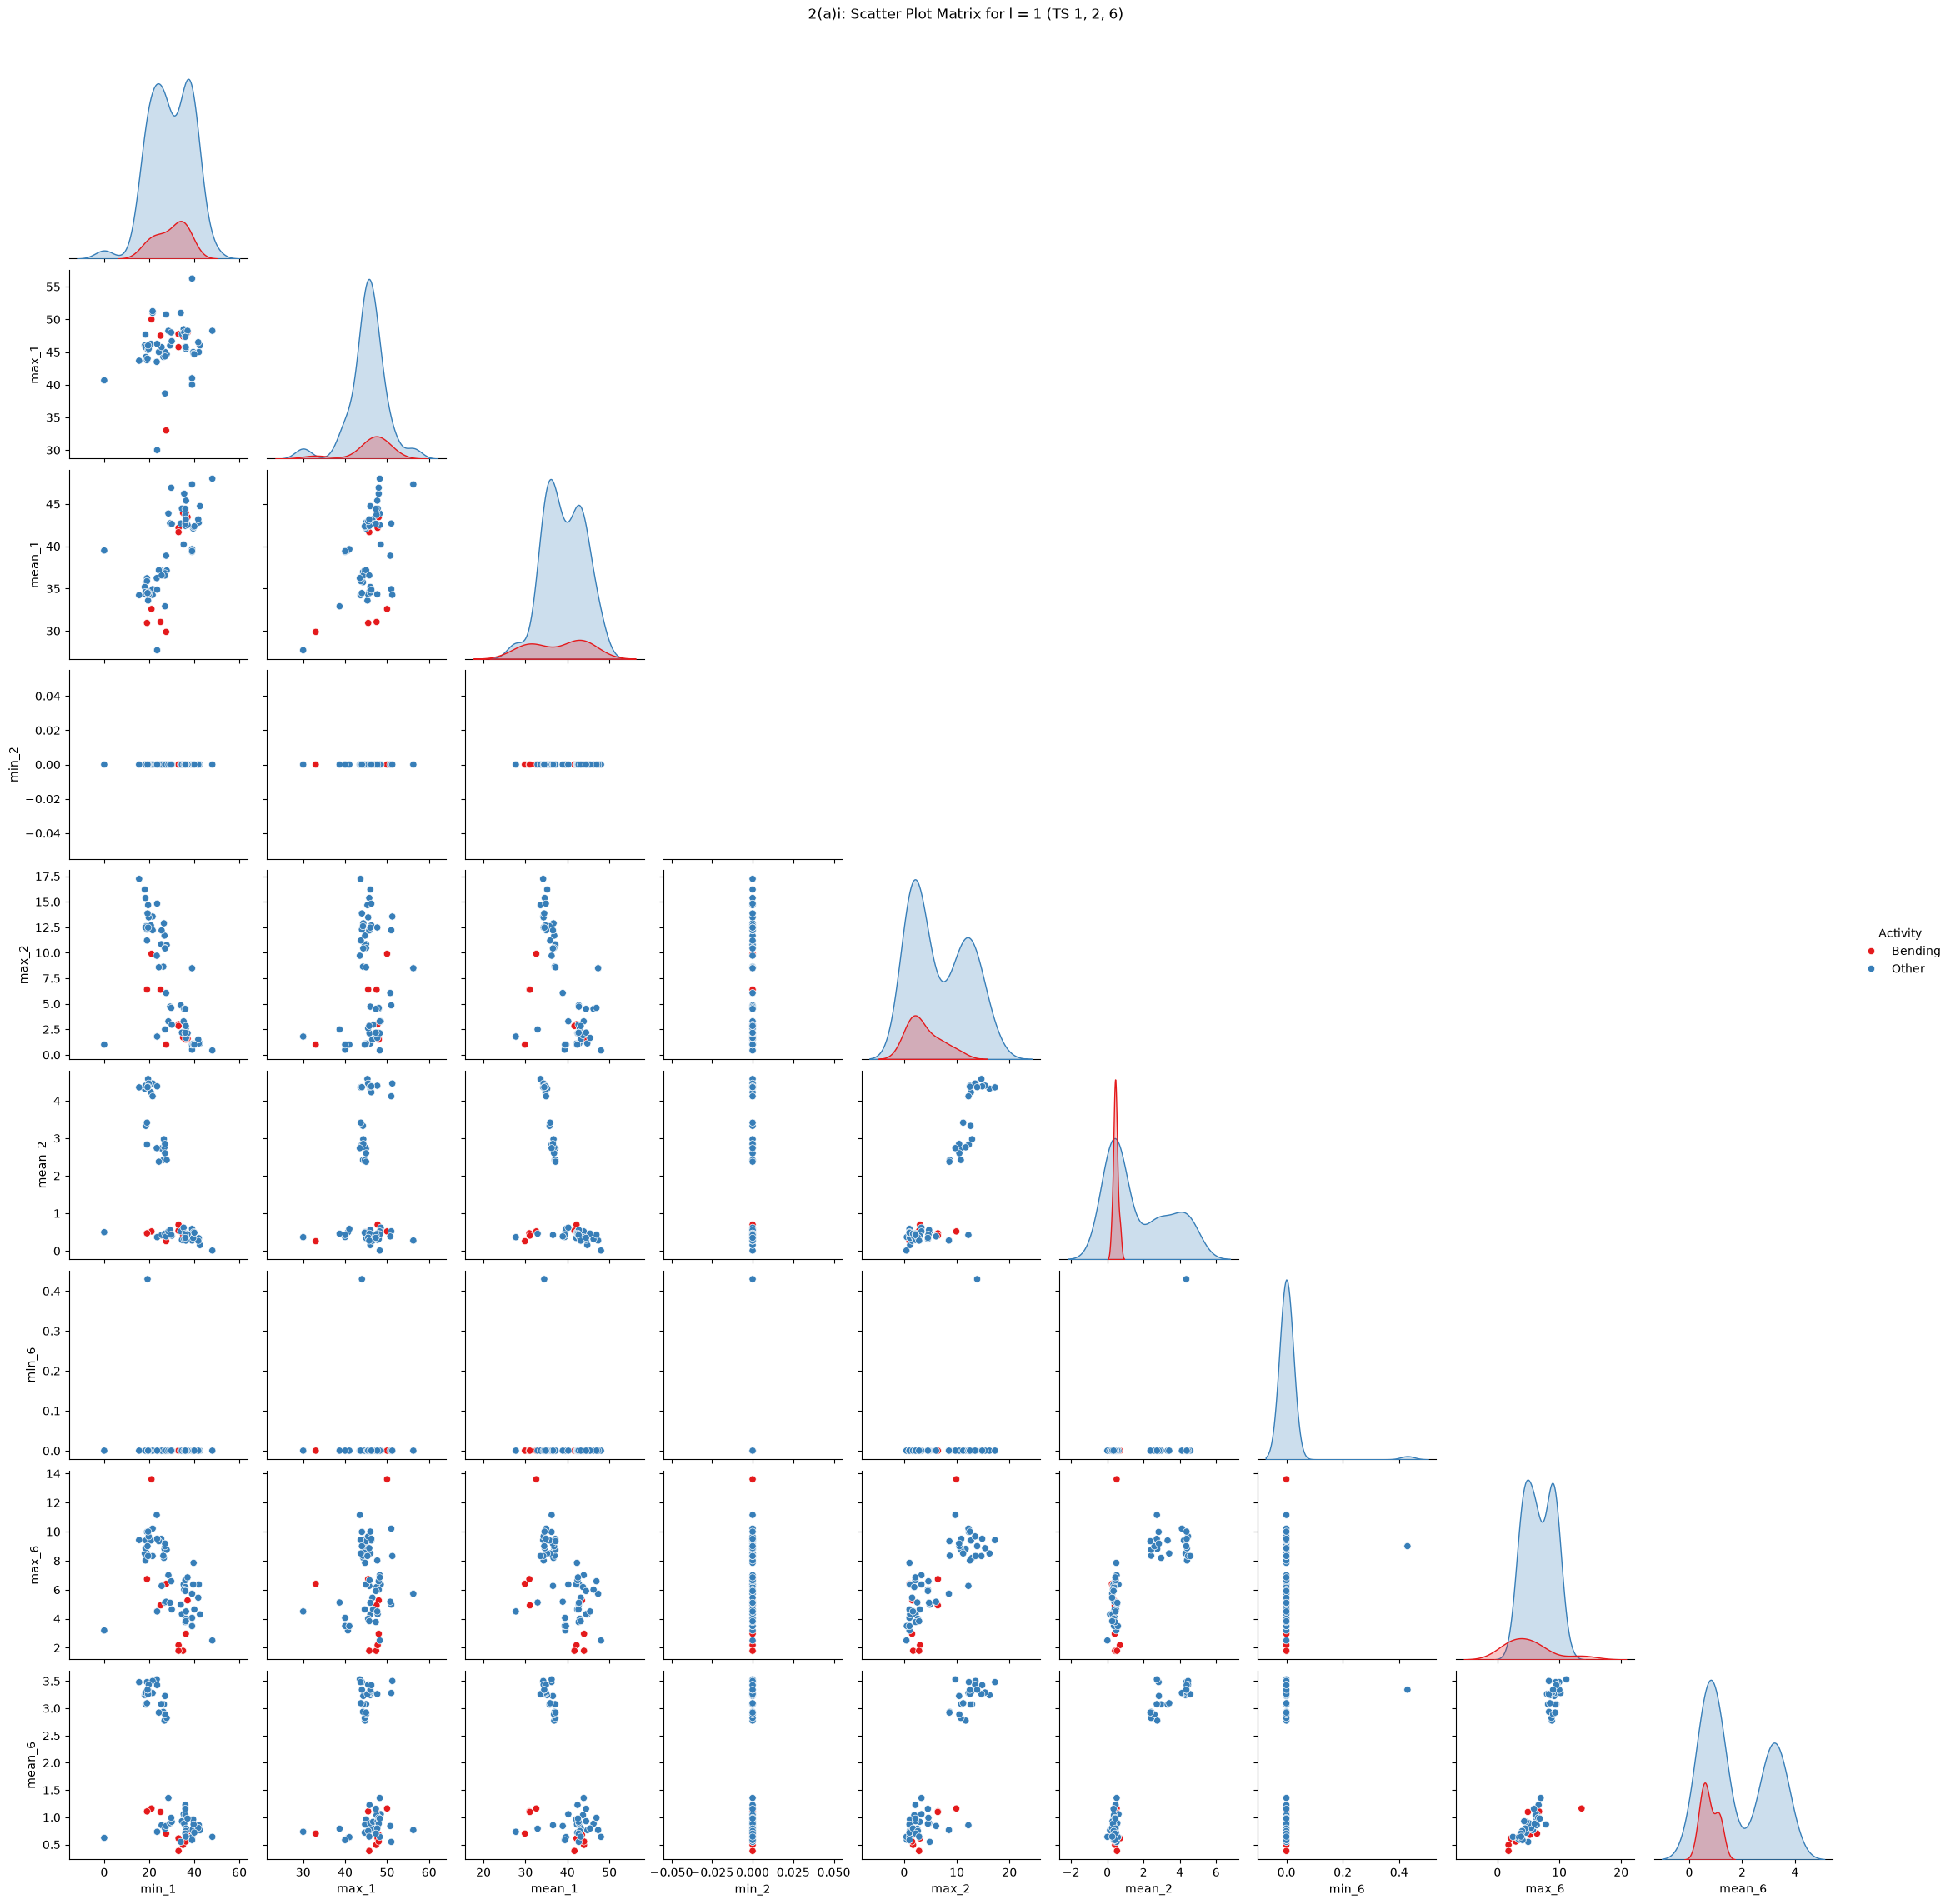

In [7]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

print("=== Starting 2(a)i: Extracting Features for l = 1 ===")

# Training rows and binary label (1 = bending)
train_meta = meta[meta["split"] == "train"].reset_index(drop=True)
train_meta["is_bending"] = (
    train_meta["activity"].isin(["bending1", "bending2"]).astype(int))
train_series = [s for s, sp in zip(series, meta["split"]) if sp == "train"]

features_2ai = []
for s in train_series:
    f_dict = {}
    for ts_idx, ts_name in [(1, "avg_rss12"), (2, "var_rss12"), (6, "var_rss23")]:
        f_dict[f"min_{ts_idx}"] = s[ts_name].min()
        f_dict[f"max_{ts_idx}"] = s[ts_name].max()
        f_dict[f"mean_{ts_idx}"] = s[ts_name].mean()
    features_2ai.append(f_dict)

df_2ai = pd.DataFrame(features_2ai)
df_2ai["Activity"] = train_meta["is_bending"].map({1: "Bending", 0: "Other"})

print(f"Extracted shape for l=1 features: {df_2ai.shape}")
print("Generating pairplot for l = 1...")

sns.pairplot(df_2ai, hue="Activity", corner=True, palette="Set1")
plt.suptitle("2(a)i: Scatter Plot Matrix for l = 1 (TS 1, 2, 6)", y=1.02)
plt.show()

### **Conclusion for 2(a)i**
* **Findings:** Bending is only partly separated from the other activities. In the `mean_2`, `mean_6` and `max_2` panels, the high-motion activities (the upper Other cluster) are far from bending, but bending points overlap with the low-motion Other points in every pair of features. Several bending instances have a low `mean_1` (about 30 to 34), but the rest fall inside the Other cluster.
* `min_2` is 0 for every instance and `min_6` is 0 for almost every instance, so these two features carry no information for separating the classes.

### 2(a)ii. Breaking Time Series into $l = 2$ Segments

We break each time series in the training set into **two approximately equal parts**. We extract `min`, `max`, and `mean` from both halves across time series 1, 2, and 6, doubling our feature space to capture localized temporal changes.

=== Starting 2(a)ii: Extracting Features for l = 2 ===
Extracted shape for l=2 features: (69, 19)


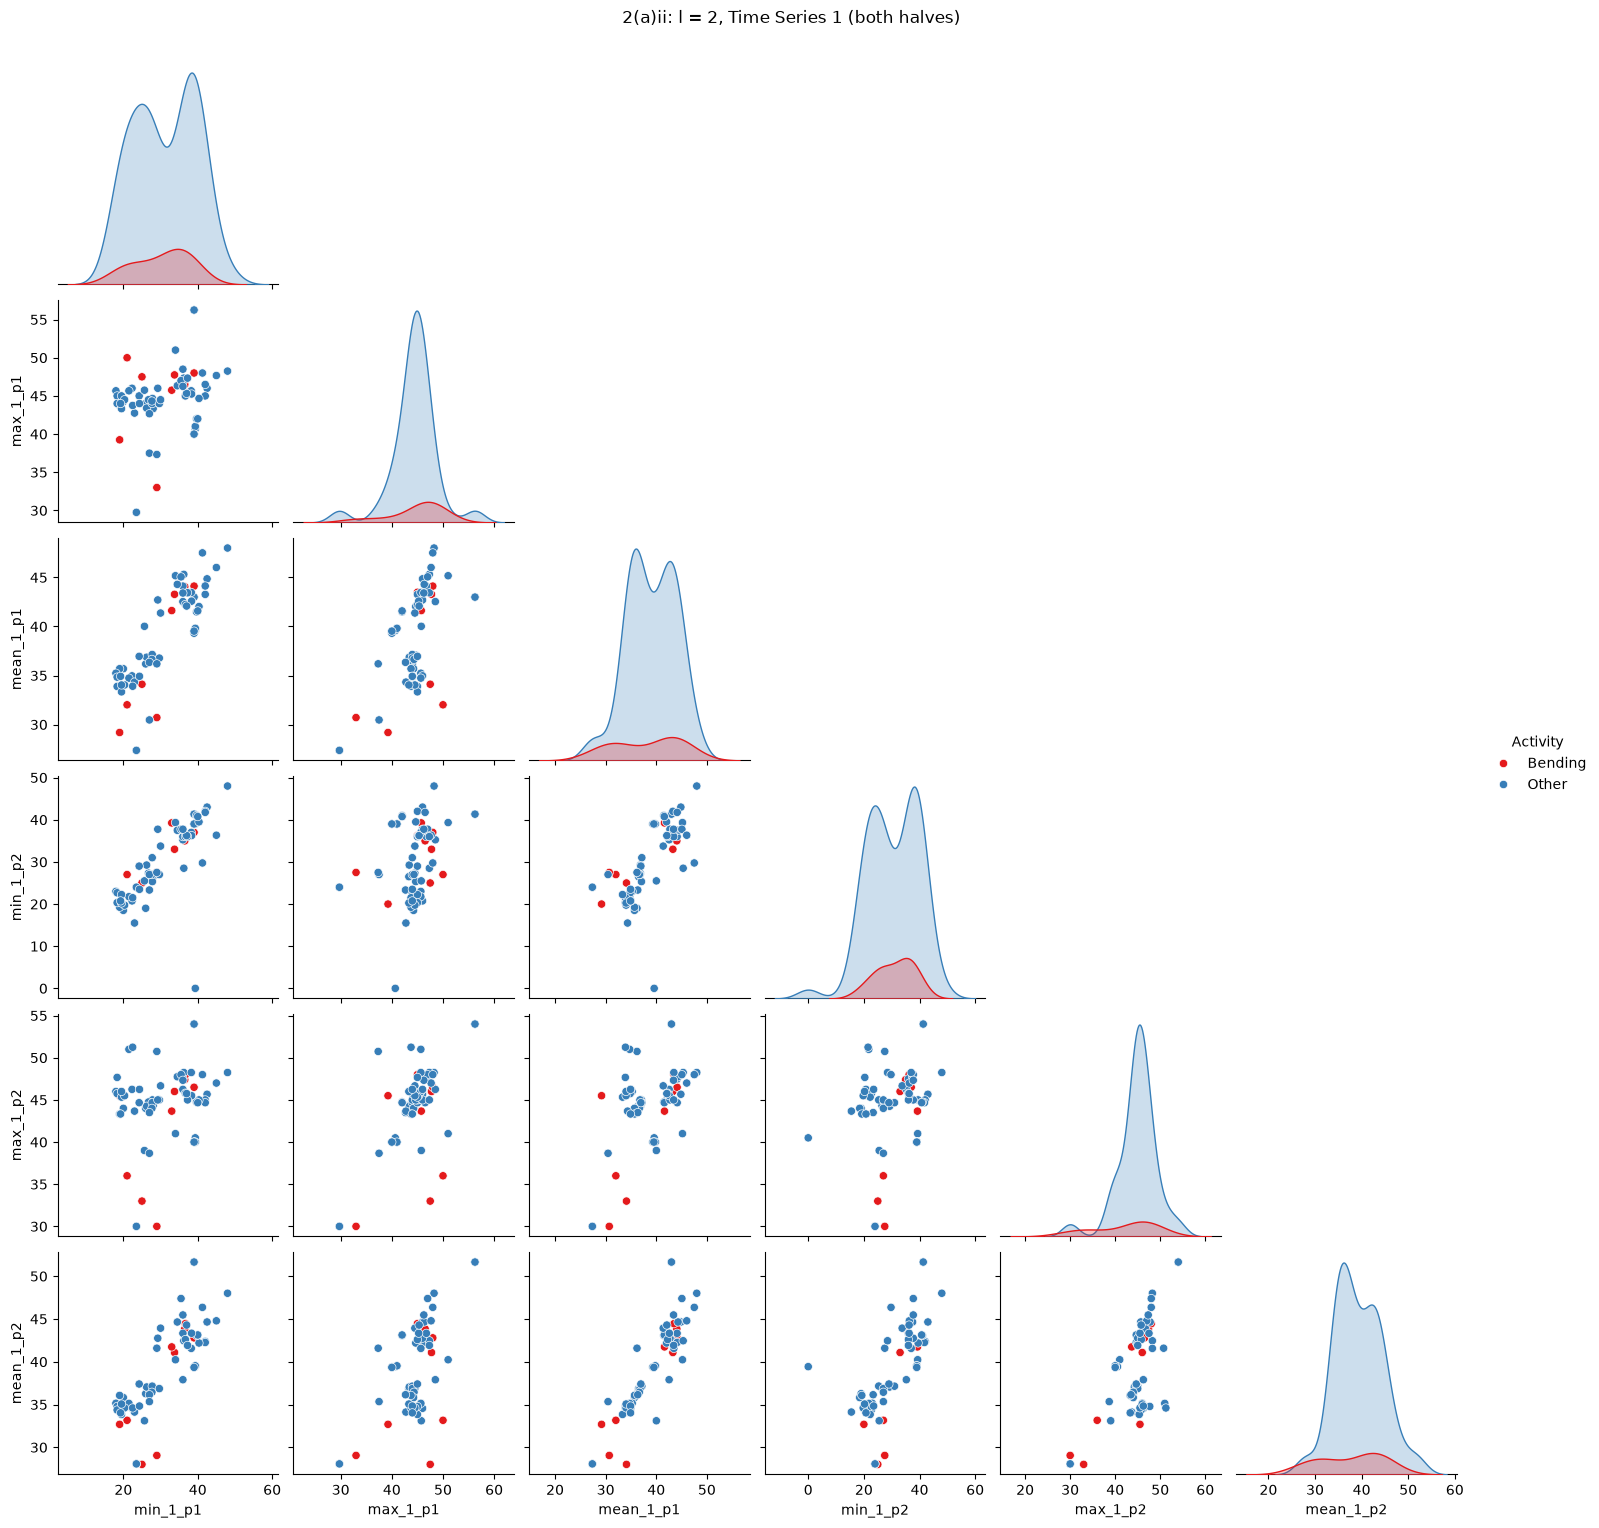

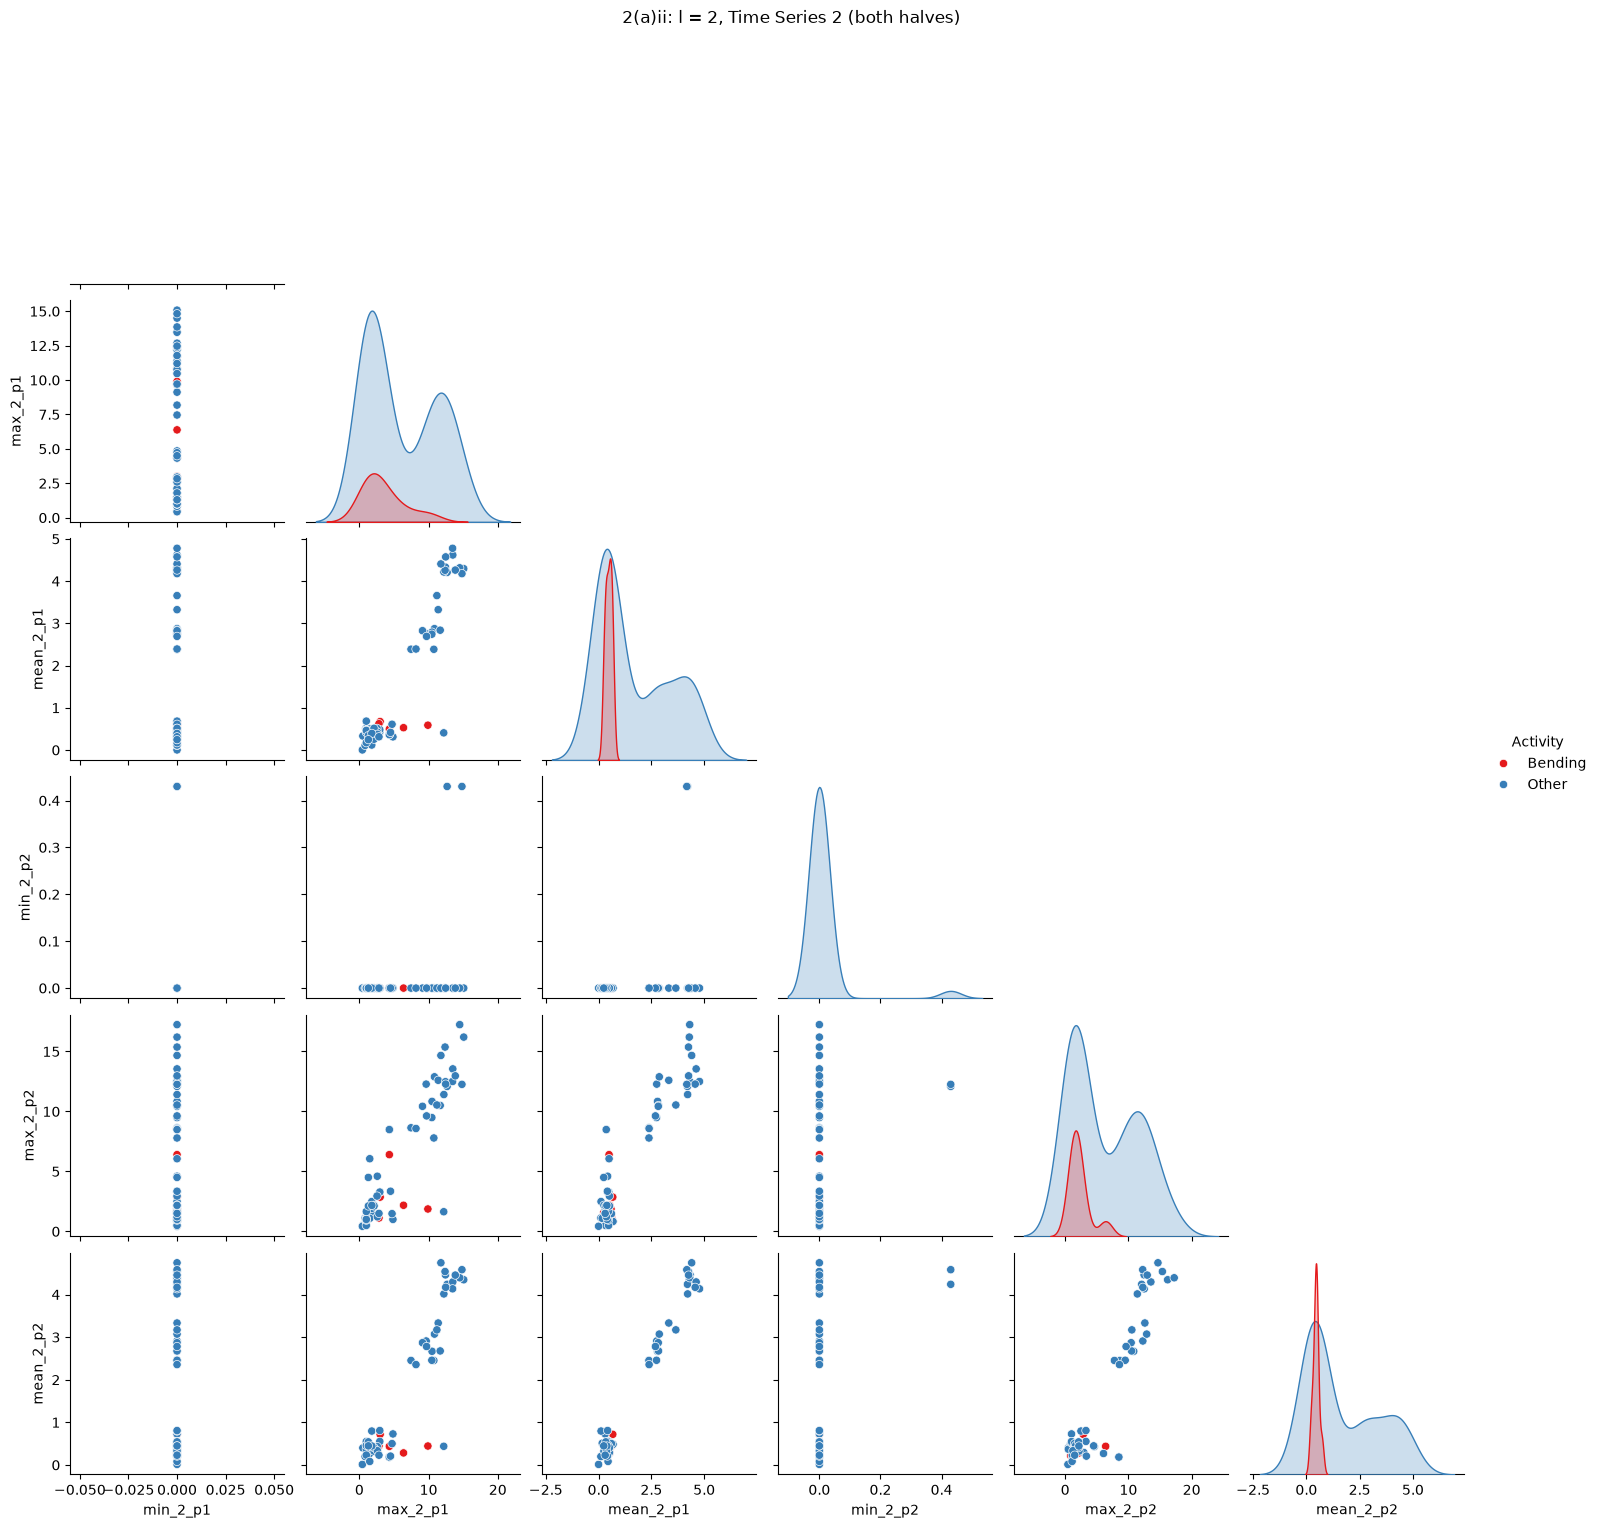

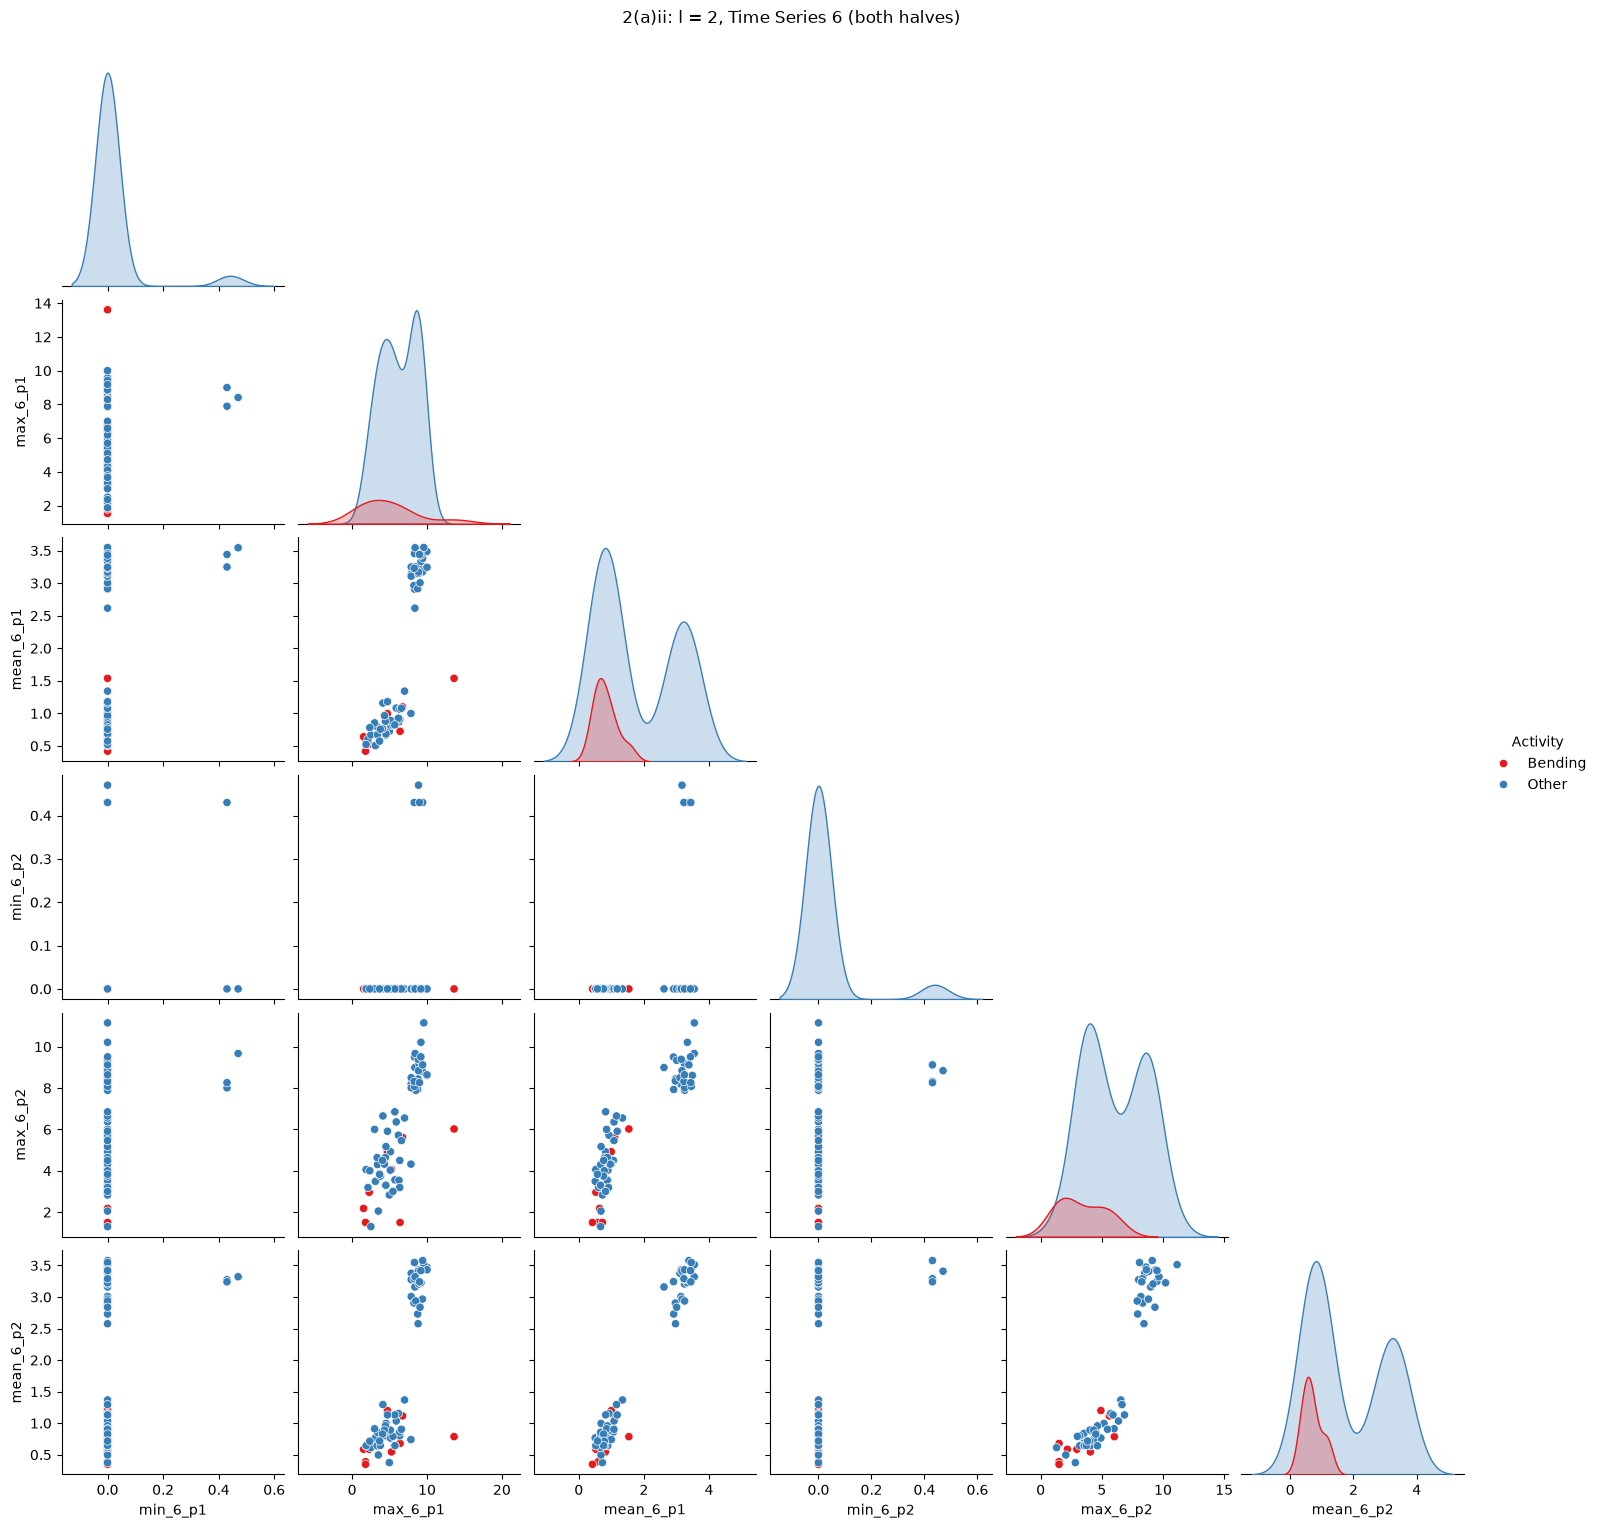

In [8]:
print("=== Starting 2(a)ii: Extracting Features for l = 2 ===")

features_2aii = []
for s in train_series:
    f_dict = {}
    half = len(s) // 2
    s1, s2 = s.iloc[:half], s.iloc[half:]

    for ts_idx, ts_name in [(1, "avg_rss12"), (2, "var_rss12"),
                            (6, "var_rss23")]:
        for part, seg in [("p1", s1), ("p2", s2)]:
            f_dict[f"min_{ts_idx}_{part}"] = seg[ts_name].min()
            f_dict[f"max_{ts_idx}_{part}"] = seg[ts_name].max()
            f_dict[f"mean_{ts_idx}_{part}"] = seg[ts_name].mean()

    features_2aii.append(f_dict)

df_2aii = pd.DataFrame(features_2aii)
df_2aii["Activity"] = train_meta["is_bending"].map({1: "Bending",
                                                     0: "Other"})

print(f"Extracted shape for l=2 features: {df_2aii.shape}")

# One plot per time series: min/max/mean of both halves
for ts_idx in [1, 2, 6]:
    cols_ts = [f"{st}_{ts_idx}_{p}" for p in ["p1", "p2"]
               for st in ["min", "max", "mean"]]
    sns.pairplot(df_2aii[cols_ts + ["Activity"]], hue="Activity",
                 corner=True, palette="Set1")
    plt.suptitle(f"2(a)ii: l = 2, Time Series {ts_idx} "
                 "(both halves)", y=1.02)
    plt.show()

### **Conclusion for 2(a)ii**
* **Do we see a considerable difference compared with 2(a)i? No.** The plots for each half of time series 1, 2 and 6 show the same pattern as the $l = 1$ plots: the high-motion activities stay well away from bending, while bending still overlaps with the low-motion activities. Each half has roughly the same min, max and mean as the whole series, so splitting adds features without adding much new separation.
* The only visible gain is in time series 1: several bending instances have a noticeably low `max_1_p2` (about 30 to 36), which separates them a little better than `max_1` did in 2(a)i. `min_2` and `min_6` remain (almost) constant at 0 in both halves.

### 2(a)iii. Cross-Validation, RFE, and Feature Selection

* **Parameter Sweep:** We test $l \in \{1, 2, \dots, 20\}$ time series segments. For each $l$, we extract all 7 time-domain features across all 6 time series ($42 \times l$ total features).
* **Right vs. Wrong Way to Perform CV:** 
  * *Wrong Way:* Running feature selection (RFE) across the entire dataset before cross-validation splits (which causes data leakage).
  * *Right Way:* Performing Stratified 5-Fold Cross-Validation where feature selection via RFE is fitted **strictly on the training folds** of each iteration.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

print("=== Starting 2(a)iii: Stratified 5-Fold CV + RFE Grid Search ===")

def extract_l_features(series_list, l):
    stats_funcs = {
        "min": lambda x: x.min(), "max": lambda x: x.max(),
        "mean": lambda x: x.mean(), "median": lambda x: x.median(),
        "std": lambda x: x.std(ddof=1), "q1": lambda x: x.quantile(0.25),
        "q3": lambda x: x.quantile(0.75)
    }
    cols = ["avg_rss12", "var_rss12", "avg_rss13",
            "var_rss13", "avg_rss23", "var_rss23"]
    rows = []
    for s in series_list:
        n = len(s)
        seg_len = n // l
        row = {}
        for seg in range(l):
            # last segment takes the leftover rows
            if seg < l - 1:
                sub_s = s.iloc[seg * seg_len:(seg + 1) * seg_len]
            else:
                sub_s = s.iloc[seg * seg_len:]
            for c_idx, col in enumerate(cols, 1):
                for name, fn in stats_funcs.items():
                    row[f"{name}_ts{c_idx}_seg{seg+1}"] = fn(sub_s[col])
        rows.append(row)
    return pd.DataFrame(rows)

y_train = train_meta["is_bending"].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)

best_score = -1
best_l = None
best_p = None
cv_scores_2aiii = {}

for l in range(1, 21):
    print(f"Processing l = {l:2d}/20...")
    X_l = extract_l_features(train_series, l)
    max_p = min(X_l.shape[1], 15)

    for p in range(1, max_p + 1):
        fold_scores = []
        for train_idx, val_idx in cv.split(X_l, y_train):
            X_tr, X_val = X_l.iloc[train_idx], X_l.iloc[val_idx]
            y_tr, y_val = y_train[train_idx], y_train[val_idx]

            # large C = effectively no L2 penalty
            model = LogisticRegression(C=1e10, max_iter=3000,
                                       solver="liblinear",
                                       random_state=552)
            selector = RFE(model, n_features_to_select=p)

            # RFE is fit on the training folds only
            X_tr_sel = selector.fit_transform(X_tr, y_tr)
            X_val_sel = selector.transform(X_val)

            model.fit(X_tr_sel, y_tr)
            fold_scores.append(
                accuracy_score(y_val, model.predict(X_val_sel)))

        avg_acc = np.mean(fold_scores)
        cv_scores_2aiii[(l, p)] = avg_acc
        if avg_acc > best_score:
            best_score = avg_acc
            best_l = l
            best_p = p

n_ties = sum(np.isclose(v, best_score) for v in cv_scores_2aiii.values())

print("\n==================================================")
print(f"Optimal Parameters Found:")
print(f"  - Best l (segments): {best_l}")
print(f"  - Best p (features): {best_p}")
print(f"  - Best CV Accuracy: {best_score:.4f}")
print(f"  - (l, p) pairs reaching this accuracy: {n_ties} "
      f"of {len(cv_scores_2aiii)}")
print("==================================================")

=== Starting 2(a)iii: Stratified 5-Fold CV + RFE Grid Search ===
Processing l =  1/20...
Processing l =  2/20...
Processing l =  3/20...
Processing l =  4/20...
Processing l =  5/20...
Processing l =  6/20...
Processing l =  7/20...
Processing l =  8/20...
Processing l =  9/20...
Processing l = 10/20...
Processing l = 11/20...
Processing l = 12/20...
Processing l = 13/20...
Processing l = 14/20...
Processing l = 15/20...
Processing l = 16/20...
Processing l = 17/20...
Processing l = 18/20...
Processing l = 19/20...
Processing l = 20/20...

Optimal Parameters Found:
  - Best l (segments): 1
  - Best p (features): 8
  - Best CV Accuracy: 1.0000
  - (l, p) pairs reaching this accuracy: 4 of 300


### **Conclusion for 2(a)iii**
* **Findings:** The best pair is **$(l, p) = (1, 8)$** with a 5-fold stratified CV accuracy of **1.0000**. Four of the 300 $(l, p)$ pairs tested reach 1.0000; the loop keeps the first one found, which is also the simplest model (smallest $l$).
* Because RFE is refit inside every training fold, the validation folds never influence which features are selected, so this CV accuracy is not inflated by data leakage. Stratification keeps bending instances in every fold (only 9 of the 69 training instances are bending).

### 2(a)iv. Training Performance, Confusion Matrix, ROC, AUC, and P-Values

We evaluate the optimal model on the training set, plotting the confusion matrix, ROC curve, and AUC. We also use `statsmodels` to print the logistic regression coefficients ($\beta$'s) and their associated p-values.

=== Starting 2(a)iv: Training Evaluation & P-Values ===
RFE Support mask summary: 8 features selected out of 42
Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 26
         Function evaluations: 29
         Gradient evaluations: 29
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       60
Method:                           MLE   Df Model:                            8
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                   1.000
Time:                        02:15:37   Log-Likelihood:            -1.4015e-05
converged:                       True   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 8.882e-09
                      coef    std err          z      P>|z|      [0.025      0.975]


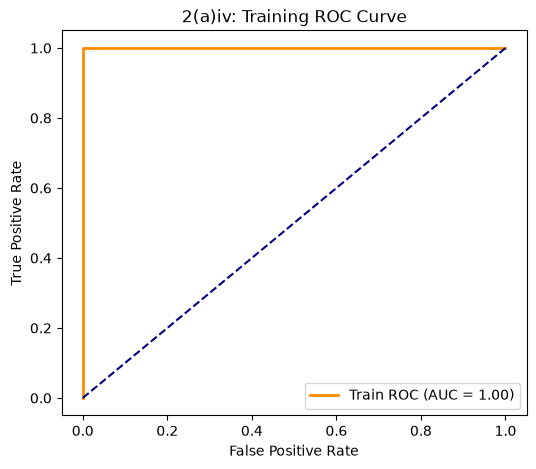

In [10]:
import statsmodels.api as sm
from sklearn.metrics import confusion_matrix, roc_curve, auc

print("=== Starting 2(a)iv: Training Evaluation & P-Values ===")

X_train_opt = extract_l_features(train_series, best_l)
model_base = LogisticRegression(C=1e10, max_iter=3000,
                                solver="liblinear", random_state=552)
rfe = RFE(model_base, n_features_to_select=best_p)
rfe = rfe.fit(X_train_opt, y_train)

print("RFE Support mask summary:", np.sum(rfe.support_),
      "features selected out of", len(rfe.support_))

X_train_selected = X_train_opt.loc[:, rfe.support_]

# p-values from statsmodels
X_train_sm = sm.add_constant(X_train_selected)
logit_model = sm.Logit(y_train, X_train_sm)
result_sm = logit_model.fit(method='bfgs', maxiter=1000)
print(result_sm.summary())

# Training-set evaluation
final_clf = LogisticRegression(C=1e10, max_iter=3000,
                               solver="liblinear", random_state=552)
final_clf.fit(X_train_selected, y_train)
y_train_pred = final_clf.predict(X_train_selected)
y_train_prob = final_clf.predict_proba(X_train_selected)[:, 1]

cm_train = confusion_matrix(y_train, y_train_pred)
fpr, tpr, _ = roc_curve(y_train, y_train_prob)
roc_auc = auc(fpr, tpr)

print("\nTraining Confusion Matrix:\n", cm_train)
print(f"Training AUC: {roc_auc:.4f}")

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Train ROC (AUC = {roc_auc:.2f})',
         color='darkorange', lw=2)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('2(a)iv: Training ROC Curve')
plt.legend(loc="lower right")
plt.show()

### **Conclusion for 2(a)iv**
* **Training performance:** the confusion matrix is $\begin{bmatrix} 60 & 0 \\ 0 & 9 \end{bmatrix}$ (no errors) and the training AUC is **1.0000**.
* **Coefficients and p-values:** the $\beta_i$'s are listed in the `statsmodels` table above (e.g. $\beta$ for `max_ts5_seg1` = 4.8496, for `q3_ts1_seg1` = $-4.2221$). Every p-value is **1.000**, and the standard errors are huge (about $6 \times 10^4$ to $6.5 \times 10^6$). `statsmodels` also reports complete separation, so the maximum likelihood estimates do not exist and these $\beta$'s and p-values cannot be interpreted.

### 2(a)v. Test Set Evaluation

We transform the **test set** using the same optimal segment parameter $l$, apply our RFE mask and trained classifier, and compare the resulting test accuracy with our cross-validation accuracy.

In [11]:
print("=== Starting 2(a)v: Test Set Evaluation ===")

test_meta = meta[meta["split"] == "test"].reset_index(drop=True)
test_meta["is_bending"] = (
    test_meta["activity"].isin(["bending1", "bending2"]).astype(int))
test_series = [s for s, sp in zip(series, meta["split"]) if sp == "test"]
y_test = test_meta["is_bending"].values

X_test_opt = extract_l_features(test_series, best_l)
X_test_selected = X_test_opt.loc[:, rfe.support_]

y_test_pred = final_clf.predict(X_test_selected)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Cross-Validation Accuracy (Optimal): {best_score:.4f}")
print(f"Test Set Accuracy: {test_accuracy:.4f}")
print("==================================================")

=== Starting 2(a)v: Test Set Evaluation ===
Cross-Validation Accuracy (Optimal): 1.0000
Test Set Accuracy: 1.0000


### **Conclusion for 2(a)v**
* **Findings:** The test accuracy (**1.0000**) is equal to the cross-validation accuracy (**1.0000**). All 19 test instances (4 bending, 15 other) are classified correctly. With only 19 test instances this agreement is encouraging, but it is not strong evidence on its own.

### 2(a)vi & 2(a)vii. Class Separation Instability & Class Imbalance

* **2(a)vi:** We analyze whether complete separation causes parameter instability (reflected by massive standard errors and p-values of $1.0$).
* **2(a)vii:** We check for class imbalance and evaluate whether case-control sampling adjustments are needed.

In [12]:
print("=== Starting 2(a)vi & 2(a)vii: Class Distribution Check ===")

# Class counts in train and test
class_counts = pd.Series(y_train).value_counts()
print(f"Training Class Distribution (0 = Other, 1 = Bending):\n"
      f"{class_counts}")

test_class_counts = pd.Series(y_test).value_counts()
print(f"\nTest Class Distribution:\n{test_class_counts}")

=== Starting 2(a)vi & 2(a)vii: Class Distribution Check ===
Training Class Distribution (0 = Other, 1 = Bending):
0    60
1     9
Name: count, dtype: int64

Test Class Distribution:
0    15
1     4
Name: count, dtype: int64


#### 2(a)vii. Case-Control Sampling Model

=== 2(a)vii: Case-Control Sampling Model ===
True prevalence pi = 0.1304, sample prevalence = 0.5000
Intercept before adjustment: -0.0385
Intercept after adjustment:  -1.9356

Train confusion matrix (rows = true 0/1):
[[51  9]
 [ 0  9]]
Train AUC: 0.9704

Test confusion matrix (rows = true 0/1):
[[13  2]
 [ 0  4]]
Test AUC: 0.9333


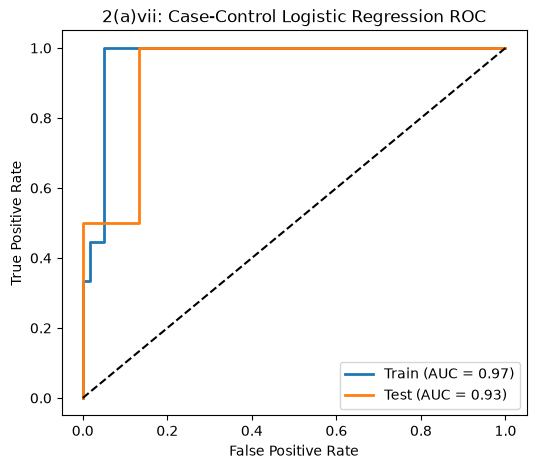

In [13]:
from sklearn.metrics import roc_auc_score

print("=== 2(a)vii: Case-Control Sampling Model ===")

# Keep every bending case, sample an equal number of controls
rng_cc = np.random.default_rng(552)
X_sel = X_train_selected.reset_index(drop=True)
pos = np.where(y_train == 1)[0]
neg = rng_cc.choice(np.where(y_train == 0)[0], size=len(pos),
                    replace=False)
idx = np.concatenate([pos, neg])

cc_model = LogisticRegression(C=1e10, max_iter=3000,
                              solver="liblinear", random_state=552)
cc_model.fit(X_sel.iloc[idx], y_train[idx])

# Intercept adjustment (ISLR 4.3.5):
# b0* = b0 + log(pi / (1 - pi)) - log(pi_s / (1 - pi_s))
pi_true = y_train.mean()
pi_samp = y_train[idx].mean()
print(f"True prevalence pi = {pi_true:.4f}, "
      f"sample prevalence = {pi_samp:.4f}")
print(f"Intercept before adjustment: {cc_model.intercept_[0]:.4f}")
cc_model.intercept_ = cc_model.intercept_ + (
    np.log(pi_true / (1 - pi_true)) - np.log(pi_samp / (1 - pi_samp)))
print(f"Intercept after adjustment:  {cc_model.intercept_[0]:.4f}")

plt.figure(figsize=(6, 5))
for name, X, y in [("Train", X_sel, y_train),
                   ("Test", X_test_selected, y_test)]:
    prob = cc_model.predict_proba(X)[:, 1]
    pred = (prob >= 0.5).astype(int)
    auc_cc = roc_auc_score(y, prob)
    print(f"\n{name} confusion matrix (rows = true 0/1):\n"
          f"{confusion_matrix(y, pred)}")
    print(f"{name} AUC: {auc_cc:.4f}")
    fpr_cc, tpr_cc, _ = roc_curve(y, prob)
    plt.plot(fpr_cc, tpr_cc, lw=2, label=f"{name} (AUC = {auc_cc:.2f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("2(a)vii: Case-Control Logistic Regression ROC")
plt.legend(loc="lower right")
plt.show()

### **Conclusion for 2(a)vi & 2(a)vii**
* **Class separation (vi): Yes.** The classes are well separated enough to make the logistic regression parameters unstable. The `statsmodels` fit reports complete separation, the log-likelihood is essentially 0 ($-1.4 \times 10^{-5}$), pseudo $R^2$ = 1.000, and the standard errors are on the order of $10^4$ to $10^6$. The model still predicts perfectly, but the individual coefficients are not reliable.
* **Class imbalance (vii): Yes.** The training confusion matrix contains 60 "other" vs. 9 "bending" instances (the test set has 15 vs. 4), so bending makes up only about 13% of the data.
* **Case-control model:** we kept all 9 bending cases, sampled 9 of the 60 controls, fit the model, and adjusted the intercept by $\log\frac{\pi}{1-\pi} - \log\frac{\tilde{\pi}}{1-\tilde{\pi}}$ with $\pi = 0.1304$ and $\tilde{\pi} = 0.5$ (intercept $-0.0385 \to -1.9356$).
  * Train: confusion matrix $\begin{bmatrix} 51 & 9 \\ 0 & 9 \end{bmatrix}$, AUC = **0.9704**.
  * Test: confusion matrix $\begin{bmatrix} 13 & 2 \\ 0 & 4 \end{bmatrix}$, AUC = **0.9333**.
  * The case-control model still catches every bending instance, but it produces more false positives than the full-data model, because it is fit on only 18 instances.

## 2(b) Binary Classification Using $\mathcal{L}_1$-Penalized Logistic Regression

We now solve the binary classification problem using $\mathcal{L}_1$-penalized (Lasso) logistic regression. Unlike manual RFE or p-value filtering, $\mathcal{L}_1$ regularization performs automated feature selection by shrinking the coefficients of uninformative features strictly to zero.

### 2(b)i. Cross-Validation for $l$ and Regularization Budget $C$

We cross-validate over two parameters:
1. **$l \in \{1, 2, \dots, 20\}$:** The number of equal segments into which each time series is split.
2. **$C$ (the regularization budget, where smaller $C$ means heavier penalty):** We use `LogisticRegressionCV` with `penalty='l1'` and `solver='liblinear'`, which automatically performs internal cross-validation across a grid of $C$ values for each segment parameter $l$.

In [14]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
print("=== Starting (b)i: L1-Penalized Logistic Regression Grid Search ===")

# Stratified 5-fold cross-validation setup
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)

best_l1_score = -1
best_l1_l = None
best_l1_C = None
l1_cv_results = []

# Loop through each l from 1 to 20
for l in range(1, 21):
    print(f"Processing l = {l:2d}/20...")
    
    # features for this l
    X_l = extract_l_features(train_series, l)
    
    # LogisticRegressionCV picks C by internal CV
    l1_cv_model = LogisticRegressionCV(
        Cs=10, 
        cv=cv_stratified, 
        penalty='l1', 
        solver='liblinear', 
        max_iter=3000, 
        random_state=552
    )
    
    l1_cv_model.fit(X_l, y_train)
    
    # mean CV accuracy for each C, then the best one
    positive_class_key = l1_cv_model.classes_[1]
    mean_scores_per_C = np.mean(l1_cv_model.scores_[positive_class_key], axis=0)
    best_mean_acc_for_l = np.max(mean_scores_per_C)
    optimal_C_for_l = l1_cv_model.C_[0]
    
    l1_cv_results.append({
        "l": l, 
        "optimal_C": optimal_C_for_l, 
        "cv_accuracy": best_mean_acc_for_l
    })
    
    print(f"  -> Optimal C: {optimal_C_for_l:.4f} | "
          f"CV Accuracy: {best_mean_acc_for_l:.4f}")
    
    if best_mean_acc_for_l > best_l1_score:
        best_l1_score = best_mean_acc_for_l
        best_l1_l = l
        best_l1_C = optimal_C_for_l

print("\n==================================================")
print(f"Optimal L1 Model Found:")
print(f"  - Best Number of Segments (l): {best_l1_l}")
print(f"  - Best Regularization Budget (C): {best_l1_C:.4f}")
print(f"  - Best Cross-Validation Accuracy: {best_l1_score:.4f}")
print("==================================================")

=== Starting (b)i: L1-Penalized Logistic Regression Grid Search ===
Processing l =  1/20...
  -> Optimal C: 0.3594 | CV Accuracy: 0.9857
Processing l =  2/20...
  -> Optimal C: 2.7826 | CV Accuracy: 0.9857
Processing l =  3/20...
  -> Optimal C: 2.7826 | CV Accuracy: 0.9714
Processing l =  4/20...
  -> Optimal C: 21.5443 | CV Accuracy: 0.9571
Processing l =  5/20...
  -> Optimal C: 0.3594 | CV Accuracy: 0.9418
Processing l =  6/20...
  -> Optimal C: 21.5443 | CV Accuracy: 0.9418
Processing l =  7/20...
  -> Optimal C: 21.5443 | CV Accuracy: 0.9571
Processing l =  8/20...
  -> Optimal C: 2.7826 | CV Accuracy: 0.9571
Processing l =  9/20...
  -> Optimal C: 2.7826 | CV Accuracy: 0.9560
Processing l = 10/20...
  -> Optimal C: 0.3594 | CV Accuracy: 0.9418
Processing l = 11/20...
  -> Optimal C: 10000.0000 | CV Accuracy: 0.9571
Processing l = 12/20...
  -> Optimal C: 21.5443 | CV Accuracy: 0.9703
Processing l = 13/20...
  -> Optimal C: 0.3594 | CV Accuracy: 0.9560
Processing l = 14/20...
  -

### **Conclusion for 2(b)i**
* **Findings:** The best $\mathcal{L}_1$ model uses **$l = 1$** with **$C = 0.3594$**, giving a 5-fold stratified CV accuracy of **0.9857**. $l = 2$ and $l = 20$ reach the same 0.9857; the loop keeps the first one found, $l = 1$, which also has the fewest features. CV accuracy generally drops as $l$ grows (as low as 0.9418), since more segments add many features but no new instances.

### 2(b)ii. Comparison: $\mathcal{L}_1$-Penalized Model vs. P-Value / RFE Feature Selection

We compare the $\mathcal{L}_1$-penalized approach with the earlier p-value / RFE approach across performance, feature sparsity, and implementation complexity.

In [15]:
from sklearn.linear_model import LogisticRegression
import warnings
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

# Final L1 model on the full training set
X_train_best_l = extract_l_features(train_series, best_l1_l)
final_l1_model = LogisticRegression(
    C=best_l1_C, 
    penalty='l1', 
    solver='liblinear', 
    max_iter=3000, 
    random_state=552
)
final_l1_model.fit(X_train_best_l, y_train)

# Number of non-zero coefficients
non_zero_features = np.sum(final_l1_model.coef_ != 0)
total_features = X_train_best_l.shape[1]

# Test set, same l
X_test_best_l = extract_l_features(test_series, best_l1_l)
y_test_pred_l1 = final_l1_model.predict(X_test_best_l)
test_accuracy_l1 = accuracy_score(y_test, y_test_pred_l1)

print(f"Total Available Features (l = {best_l1_l}): {total_features}")
print(f"Features Selected by L1 Penalty (Non-zero coefficients): "
      f"{non_zero_features}")
print(f"L1-Penalized Test Set Accuracy: {test_accuracy_l1:.4f}")
print(f"Previous RFE / P-Value Test Accuracy: {test_accuracy:.4f}")
print("==================================================")

Total Available Features (l = 1): 42
Features Selected by L1 Penalty (Non-zero coefficients): 5
L1-Penalized Test Set Accuracy: 1.0000
Previous RFE / P-Value Test Accuracy: 1.0000


### **Conclusion for 2(b)ii**
* **Which one performs better?** On the test set they are tied: both reach **1.0000** test accuracy. The RFE model has a slightly higher CV accuracy (1.0000 vs. 0.9857), but the $\mathcal{L}_1$ model is sparser, using **5** non-zero coefficients out of 42 versus **8** features for RFE. The p-values themselves were not usable for variable selection here: complete separation made every p-value equal to 1.000, while the $\mathcal{L}_1$ penalty keeps the coefficients finite and stable.
* **Which one is easier to implement?** **$\mathcal{L}_1$-penalized logistic regression.** `LogisticRegressionCV` selects $C$ by cross-validation internally, and the penalty performs feature selection in the same fit. The p-value / RFE approach needs a separate loop over $(l, p)$ with feature selection refit inside every fold.

## 2(c) Multi-class Classification (The Realistic Case)

We now expand our classification task from binary to **multi-class classification**, aiming to classify all 7 individual activity categories (`bending1`, `bending2`, `cycling`, `lying`, `sitting`, `standing`, `walking`) in the dataset.

### 2(c)i. $\mathcal{L}_1$-Penalized Multinomial Regression, Test Error, Multiclass Confusion Matrix, and ROC/AUC

* **Model:** multinomial logistic regression with an $\mathcal{L}_1$ penalty, fit with the `saga` solver (liblinear does not support the multinomial loss).
* **Hyperparameter search:** as in 2(b)i, we cross-validate over both $l \in \{1, \dots, 20\}$ and $C$, using stratified 5-fold CV and multiclass accuracy.
* **Standardization:** features are standardized so the $\mathcal{L}_1$ penalty treats them on the same scale. The scaler is inside the pipeline, so it is fit on the training folds only.
* **Multiclass metrics:** we report the test error, the $7 \times 7$ confusion matrix, and one-vs-rest ROC curves with per-class AUCs.

=== Starting 2(c)i: L1-Penalized Multinomial Regression ===
l =  1 | Optimal C:    5.9948 | CV Accuracy: 0.9132
l =  2 | Optimal C:  278.2559 | CV Accuracy: 0.9429
l =  3 | Optimal C:   21.5443 | CV Accuracy: 0.8835
l =  4 | Optimal C:   77.4264 | CV Accuracy: 0.8989
l =  5 | Optimal C:    5.9948 | CV Accuracy: 0.8549
l =  6 | Optimal C: 1000.0000 | CV Accuracy: 0.8989
l =  7 | Optimal C:   77.4264 | CV Accuracy: 0.8253
l =  8 | Optimal C:  278.2559 | CV Accuracy: 0.8549
l =  9 | Optimal C:   77.4264 | CV Accuracy: 0.8549
l = 10 | Optimal C:   77.4264 | CV Accuracy: 0.8692
l = 11 | Optimal C:  278.2559 | CV Accuracy: 0.8396
l = 12 | Optimal C:  278.2559 | CV Accuracy: 0.8396
l = 13 | Optimal C:   77.4264 | CV Accuracy: 0.7813
l = 14 | Optimal C:   77.4264 | CV Accuracy: 0.8538
l = 15 | Optimal C:    1.6681 | CV Accuracy: 0.8264
l = 16 | Optimal C:   77.4264 | CV Accuracy: 0.8560
l = 17 | Optimal C:   77.4264 | CV Accuracy: 0.8110
l = 18 | Optimal C:  278.2559 | CV Accuracy: 0.8407
l = 

,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,1,0,0,1,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,3,0,0,0
sitting,1,0,0,0,1,1,0
standing,0,0,0,0,0,3,0
walking,0,0,0,0,0,0,3


AUC (bending1): 1.0000
AUC (bending2): 0.9706
AUC (cycling): 1.0000
AUC (lying): 1.0000
AUC (sitting): 0.9167
AUC (standing): 1.0000
AUC (walking): 1.0000
Macro-average one-vs-rest AUC: 0.9839


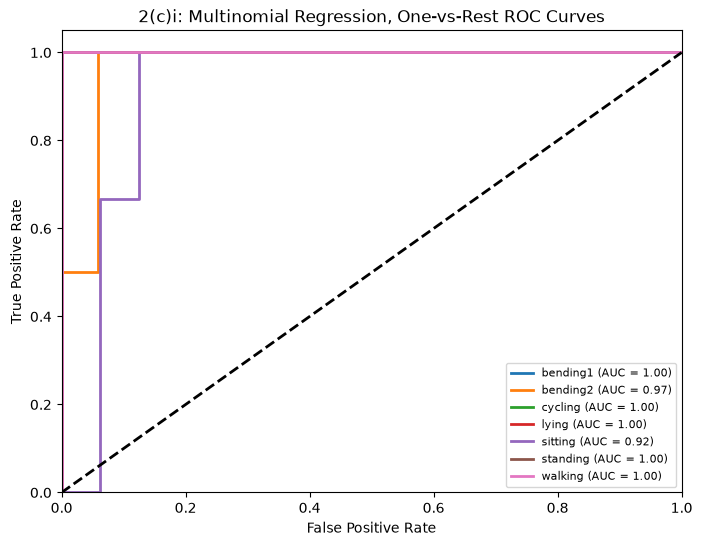

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             roc_curve, auc, roc_auc_score)
from sklearn.exceptions import ConvergenceWarning
import warnings
warnings.filterwarnings("ignore", category=ConvergenceWarning)

print("=== Starting 2(c)i: L1-Penalized Multinomial Regression ===")

y_train_multi = train_meta["activity"].to_numpy(dtype=str)
y_test_multi = test_meta["activity"].to_numpy(dtype=str)
classes = np.unique(y_train_multi)

cv_stratified = StratifiedKFold(n_splits=5, shuffle=True,
                                random_state=552)
Cs = np.logspace(-2, 3, 10)

best_c_score = -1
best_c_l = None
best_c_C = None
best_c_model = None

for l in range(1, 21):
    X_l_train = extract_l_features(train_series, l)

    # scaler inside the pipeline, so it is fit on training folds only
    pipe = make_pipeline(
        StandardScaler(),
        LogisticRegression(penalty="l1", solver="saga", tol=1e-3,
                           max_iter=2000, random_state=552))
    gs = GridSearchCV(pipe, {"logisticregression__C": Cs},
                      cv=cv_stratified, scoring="accuracy")
    gs.fit(X_l_train, y_train_multi)

    C_l = gs.best_params_["logisticregression__C"]
    print(f"l = {l:2d} | Optimal C: {C_l:9.4f} | "
          f"CV Accuracy: {gs.best_score_:.4f}")

    if gs.best_score_ > best_c_score:
        best_c_score = gs.best_score_
        best_c_l = l
        best_c_C = C_l
        best_c_model = gs.best_estimator_

print(f"\n==================================================")
print(f"Optimal Multinomial L1 Model Found:")
print(f"  - Best Number of Segments (l): {best_c_l}")
print(f"  - Best Regularization Budget (C): {best_c_C:.4f}")
print(f"  - Best Cross-Validation Accuracy: {best_c_score:.4f}")
print(f"==================================================")

# best_c_model was refit on the full training set by GridSearchCV
X_test_opt_multi = extract_l_features(test_series, best_c_l)
y_pred_multi = best_c_model.predict(X_test_opt_multi)
test_error_multi = 1.0 - accuracy_score(y_test_multi, y_pred_multi)

print(f"Multi-class Test Error: {test_error_multi:.4f}")
print(f"Multi-class Test Accuracy: {1.0 - test_error_multi:.4f}")

cm_multi = confusion_matrix(y_test_multi, y_pred_multi, labels=classes)
print("\nMulticlass Confusion Matrix (rows = true, columns = predicted):")
display(pd.DataFrame(cm_multi, index=classes, columns=classes))

# One-vs-rest ROC curve for each class
y_test_bin = label_binarize(y_test_multi, classes=classes)
y_score_multi = best_c_model.predict_proba(X_test_opt_multi)

plt.figure(figsize=(8, 6))
for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score_multi[:, i])
    roc_auc_val = auc(fpr, tpr)
    print(f"AUC ({cls}): {roc_auc_val:.4f}")
    plt.plot(fpr, tpr, lw=2, label=f"{cls} (AUC = {roc_auc_val:.2f})")

macro_auc_multi = roc_auc_score(y_test_multi, y_score_multi,
                                multi_class="ovr", average="macro")
print(f"Macro-average one-vs-rest AUC: {macro_auc_multi:.4f}")

plt.plot([0, 1], [0, 1], "k--", lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("2(c)i: Multinomial Regression, One-vs-Rest ROC Curves")
plt.legend(loc="lower right", fontsize=8)
plt.show()

### **Conclusion for 2(c)i**
* **Best model:** $l = 2$, $C = 278.2559$, CV accuracy **0.9429**.
* **Test error: 0.1579** (accuracy 0.8421, 3 of 19 test instances misclassified). From the confusion matrix, one `bending2` instance is predicted as `sitting`, and two `sitting` instances are predicted as `bending1` and `standing`. Cycling, lying, standing and walking are all classified correctly. The errors are among the low-motion activities, which matches the overlap seen in the 2(a) scatter plots.
* **How multiclass confusion matrices and ROC curves are defined:** the multiclass confusion matrix is a $K \times K$ table whose entry $(i, j)$ counts test instances of true class $i$ predicted as class $j$; correct predictions lie on the diagonal. ROC curves are defined one-vs-rest: for each class $k$, that class is treated as positive and all others as negative, and the predicted probability of class $k$ is used as the score. This gives one ROC curve and one AUC per class, which can be averaged (macro-average AUC).
* **AUCs:** 1.0000 for bending1, cycling, lying, standing and walking, 0.9706 for bending2, and 0.9167 for sitting; macro-average AUC = **0.9839**.

### 2(c)ii. Naive Bayes Classifier (Gaussian vs. Multinomial Priors)

We repeat 2(c)i with a **Naive Bayes classifier**, choosing $l$ by the same stratified 5-fold CV, for two assumptions:
1. **Gaussian Naive Bayes (`GaussianNB`):** each feature is normally distributed within each class.
2. **Multinomial Naive Bayes (`MultinomialNB`):** designed for counts/frequencies, so it requires non-negative inputs; features are min-max scaled to $[0, 1]$ inside the pipeline.

In [18]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score

print("=== Starting 2(c)ii: Naive Bayes Classifier Evaluation ===")

# MultinomialNB needs non-negative inputs, so features are min-max scaled
nb_models = {
    "Gaussian NB": lambda: GaussianNB(),
    "Multinomial NB": lambda: make_pipeline(MinMaxScaler(clip=True),
                                            MultinomialNB()),
}

nb_results = {}
for name, make_model in nb_models.items():
    best_nb = {"score": -1}
    for l in range(1, 21):
        X_l = extract_l_features(train_series, l)
        score = cross_val_score(make_model(), X_l, y_train_multi,
                                cv=cv_stratified,
                                scoring="accuracy").mean()
        if score > best_nb["score"]:
            best_nb = {"l": l, "score": score}

    model = make_model()
    model.fit(extract_l_features(train_series, best_nb["l"]),
              y_train_multi)
    X_te = extract_l_features(test_series, best_nb["l"])
    pred = model.predict(X_te)
    err = 1.0 - accuracy_score(y_test_multi, pred)
    nb_results[name] = {"l": best_nb["l"], "cv_acc": best_nb["score"],
                        "test_err": err}

    print(f"\n{name}: best l = {best_nb['l']}, "
          f"CV accuracy = {best_nb['score']:.4f}, "
          f"test error = {err:.4f}")
    print("Confusion matrix (rows = true, columns = predicted):")
    display(pd.DataFrame(
        confusion_matrix(y_test_multi, pred, labels=classes),
        index=classes, columns=classes))

gnb_err = nb_results["Gaussian NB"]["test_err"]
mnb_err = nb_results["Multinomial NB"]["test_err"]
print("==================================================")

=== Starting 2(c)ii: Naive Bayes Classifier Evaluation ===

Gaussian NB: best l = 1, CV accuracy = 0.8692, test error = 0.1053
Confusion matrix (rows = true, columns = predicted):


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,2,0,0,0,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,2,1,0,0
sitting,0,0,0,0,3,0,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3



Multinomial NB: best l = 5, CV accuracy = 0.7527, test error = 0.2632
Confusion matrix (rows = true, columns = predicted):


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,1,0,0,0,1,0,0
cycling,0,0,3,0,0,0,0
lying,0,1,0,2,0,0,0
sitting,0,0,0,0,2,1,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3


### **Conclusion for 2(c)ii**
* **Gaussian NB:** best $l = 1$, CV accuracy 0.8692, **test error 0.1053** (2 of 19 misclassified: one `lying` and one `standing` instance predicted as `sitting`).
* **Multinomial NB:** best $l = 5$, CV accuracy 0.7527, **test error 0.2632** (5 of 19 misclassified, mostly among bending2, lying, sitting and standing).
* **Comparison:** Gaussian NB is clearly better on both CV accuracy and test error. Our features are continuous summary statistics, which suits the Gaussian assumption. The multinomial model treats the scaled features as if they were counts, which does not match how these features are generated.

### 2(c)iii. Method Comparison for Multi-class Classification

We compare $\mathcal{L}_1$-penalized multinomial regression against Naive Bayes classifiers to determine which method is superior for this multi-class time series problem.

In [ ]:
print("=== Starting 2(c)iii: Final Method Comparison ===")

comparison = pd.DataFrame({
    "best l": [best_c_l, nb_results["Gaussian NB"]["l"],
               nb_results["Multinomial NB"]["l"]],
    "CV accuracy": [best_c_score, nb_results["Gaussian NB"]["cv_acc"],
                    nb_results["Multinomial NB"]["cv_acc"]],
    "Test error": [test_error_multi, gnb_err, mnb_err],
}, index=["L1 multinomial regression", "Gaussian NB", "Multinomial NB"])
display(comparison.round(4))

### **Conclusion and Final Verdict for 2(c)iii**
| Method | Best $l$ | CV accuracy | Test error |
|---|---|---|---|
| $\mathcal{L}_1$ multinomial regression | 2 | 0.9429 | 0.1579 |
| Gaussian NB | 1 | 0.8692 | 0.1053 |
| Multinomial NB | 5 | 0.7527 | 0.2632 |

* **Which method is better?** On the held-out test set, **Gaussian Naive Bayes is best** (test error 0.1053 vs. 0.1579 for $\mathcal{L}_1$ multinomial regression). The test set is the fairer comparison, because each CV score was used to tune its model, and the regression was tuned over 200 $(l, C)$ combinations, so its CV accuracy of 0.9429 is optimistic.
* The gap is only one test instance (2 vs. 3 errors out of 19), so the two methods are close; $\mathcal{L}_1$ regression has the higher CV accuracy and a macro AUC of 0.9839. Multinomial NB is clearly the worst on both measures.

## 3. ISLR Exercise 4.8.3

This exercise relates to the QDA model, where observations within each class are drawn from a normal distribution with a class-specific mean and class-specific variance. We prove that the Bayes' classifier is quadratic (not linear) in the case where $p = 1$.

### **Mathematical Proof / Solution (ISLR 4.8.3)**

1. **Bayes' Theorem Setup:** 
   For $K$ classes, the posterior probability $P(Y = k \mid X = x)$ is given by Bayes' theorem:
   $$p_k(x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^{K} \pi_l f_l(x)}$$

2. **Gaussian Density Function ($p = 1$):**
   Assuming each class $k$ has mean $\mu_k$ and variance $\sigma_k^2$:
   $$f_k(x) = \frac{1}{\sqrt{2\pi}\sigma_k} \exp\left( -\frac{(x - \mu_k)^2}{2\sigma_k^2} \right)$$

3. **Log-Posterior Discriminant Function:**
   Taking the natural logarithm of $p_k(x)$ (and omitting terms independent of $k$) yields the quadratic discriminant function $\delta_k(x)$:
   $$\delta_k(x) = -\frac{1}{2}\log(\sigma_k^2) - \frac{(x - \mu_k)^2}{2\sigma_k^2} + \log(\pi_k)$$
   Expanding the square gives
   $$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{x\mu_k}{\sigma_k^2} - \frac{\mu_k^2}{2\sigma_k^2} - \log(\sigma_k) + \log(\pi_k)$$
   so $\delta_k(x)$ contains terms in $x^2$, $x$, and constants. Because the coefficient of $x^2$ depends on $\sigma_k^2$ (which varies across classes), it does not cancel out. Thus, the decision boundary is **quadratic**, not linear.

## 4. ISLR Exercise 4.8.7

Suppose we examine companies and find that the mean value of last year's percentage profit ($X$) for companies that issued a dividend was $\bar{X}_{\text{Yes}} = 10$, while the mean for those that didn't was $\bar{X}_{\text{No}} = 0$. The variance is $\hat{\sigma}^2 = 36$ for both groups, and $80\%$ of companies issued dividends ($\pi_{\text{Yes}} = 0.8$, $\pi_{\text{No}} = 0.2$). Assuming $X$ follows a normal distribution, we predict the probability that a company will issue a dividend this year given $X = 4$.

In [ ]:
import numpy as np
import scipy.stats as stats

print("=== Starting ISLR Exercise 4.8.7 Calculation ===")

# Given parameters from the problem description
mu_yes = 10.0
mu_no = 0.0
variance = 36.0
sigma = np.sqrt(variance)

pi_yes = 0.8
pi_no = 0.2

x_val = 4.0

# Compute likelihoods f_k(x) using the normal probability density function
f_yes = stats.norm.pdf(x_val, loc=mu_yes, scale=sigma)
f_no = stats.norm.pdf(x_val, loc=mu_no, scale=sigma)

# Apply Bayes' theorem to find posterior probability P(Y = "Yes" | X = 4)
numerator = pi_yes * f_yes
denominator = (pi_yes * f_yes) + (pi_no * f_no)
prob_yes_given_x = numerator / denominator

print(f"Likelihood f(X=4 | Yes): {f_yes:.6f}")
print(f"Likelihood f(X=4 | No):  {f_no:.6f}")
print(f"Predicted Probability P(Dividend = Yes | X = 4): "
      f"{prob_yes_given_x:.4f} ({prob_yes_given_x * 100:.2f}%)")
print("==================================================")

### **Conclusion for ISLR Exercise 4.8.7**
* **Findings:** Plugging the parameters into Bayes' theorem yields a predicted probability of approximately **$0.752$ (or $75.2\%$**) that a company will issue a dividend this year given that its percentage profit was $4$ last year. 
* **Interpretation:** Even though a profit of $4$ is closer to the non-dividend mean ($0$) than the dividend mean ($10$), the strong prior probability favoring dividend-issuing companies ($\pi_{\text{Yes}} = 0.8$ vs $\pi_{\text{No}} = 0.2$) heavily weights the outcome toward predicting "Yes".